# 03 — Feature Engineering

**Goal** – Build a single feature matrix for the TikTok engagement prediction task,
analyse each feature's distribution and null rate, identify near-duplicate feature
pairs (|r| > 0.8), compute a Spearman-correlation sanity check against the relative
target (train only), and flag features that are (nearly) constant within creators
— those are uninformative for per-creator models even if useful globally.

**Input** – `data/raw/*.parquet` + `config/default.yaml`.
Non-monotonic videos and creators below the min-threshold are excluded before
building targets and features.

**Conclusion** –
Starting with 209 543 videos, 1 240 non-monotonic videos are removed (data-reset
artefacts), then 1 687 videos from creators with < 30 videos are dropped, leaving
**200 616 videos × 1 437 creators**. The feature matrix has **54 columns** (50
numeric, 4 categorical: `ratio`, `topic`, `music_selected_from`, `dominant_emotion`).

*Null rates*: Hook features (`hook_first_sentence_*`) and `transcript_n_words` have
~59.8 % null (matches `has_transcript = 0`). `speaking_rate` has 37.7 % null.
All other features are ≤ 1.4 % null. Nulls are not imputed — XGBoost handles them.

*Near-duplicate pairs* (|Pearson r| > 0.8):
`transcript_n_words ↔ hook_first_sentence_len` (r = 0.94),
`desc_len ↔ desc_n_words` (r = 0.93),
`has_transcript ↔ speaking_rate` (r = 0.90),
`duration_log ↔ transcript_n_words` (r = 0.82).
Recommendation: keep one from each pair; drop `hook_first_sentence_len` (already
noted as unreliable), `desc_n_words`, and use `has_transcript` as the binary flag
while keeping `speaking_rate` for videos that have it.

*Per-creator constancy* (features useless for per-creator model):
`is_ads` (always 0 — zero variance globally too) and
`hook_first_sentence_is_question` (100 % of creators have constant value — mostly
NaN). All top-20 hashtag indicators have 75–89 % of creators constant (hashtags
are per-creator niche, not within-creator signal). `created_by_ai` is constant for
86 % of creators. These features are valuable for the **global** model but should be
excluded from per-creator models.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


In [3]:
from creator_analytics.config import load_config
from creator_analytics.data import (
    filter_creators, load_raw_table, train_test_split_by_creator,
)
from creator_analytics.features import (
    FEATURE_DESCRIPTIONS, build_features, follower_asof_join,
)
from creator_analytics.targets import build_target, get_nonmonotonic_video_ids

cfg    = load_config("config/default.yaml")
RAW    = cfg["paths"]["raw_dir"]
FIGS   = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")
print(f"videos {len(videos):,}  creator_daily {len(creator_daily):,}  engagement {len(engagement):,}")


videos 209,543  creator_daily 278,433  engagement 6,068,955


## Step 0 — Data quality checks and pre-filtering

In [4]:
# --- Fix 1: non-monotonic videos ---
bad_ids  = get_nonmonotonic_video_ids(engagement)
print(f"Non-monotonic videos (play_count drops): {len(bad_ids):,}")
videos_clean = videos[~videos["video_id"].isin(bad_ids)].reset_index(drop=True)
print(f"Videos after removing non-monotonic: {len(videos_clean):,}")

# --- Fix 2: filter creators ---
min_vids = cfg["data"]["min_videos_per_creator"]
videos_f = filter_creators(videos_clean, "author_id", min_videos=min_vids)
print(f"Videos after min={min_vids} filter: {len(videos_f):,}  "
      f"creators: {videos_f['author_id'].nunique():,}")

# --- Fix 3: build_target scope check ---
abs_t_all   = build_target(engagement, videos,   day=14, mode="absolute")
abs_t_filt  = build_target(engagement, videos_f, day=14, mode="absolute")
print(f"\nbuild_target scope check:")
print(f"  all videos     → {len(abs_t_all):,} rows")
print(f"  filtered videos → {len(abs_t_filt):,} rows  (must equal {len(videos_f):,})")
assert len(abs_t_filt) == len(videos_f), "build_target returned more rows than videos passed!"


Non-monotonic videos (play_count drops): 1,240
Videos after removing non-monotonic: 208,303


Videos after min=30 filter: 200,616  creators: 1,437



build_target scope check:
  all videos     → 209,543 rows
  filtered videos → 200,616 rows  (must equal 200,616)


## Step 0b — follower_asof_join: as-of direction and coverage

In [5]:
import pandas as pd

vids_diag = videos_f[["video_id", "author_id", "create_date"]].copy()
vids_diag["_vdt"] = pd.to_datetime(vids_diag["create_date"])

crd_diag  = creator_daily[["author_id", "date", "follower_count"]].copy()
crd_diag["_cdt"] = pd.to_datetime(crd_diag["date"])

vids_s = vids_diag.sort_values("_vdt")
crd_s  = crd_diag.dropna(subset=["_cdt"]).sort_values("_cdt")

merged_diag = pd.merge_asof(
    vids_s,
    crd_s[["author_id", "_cdt", "follower_count"]],
    left_on="_vdt", right_on="_cdt",
    by="author_id", direction="backward",
)
merged_diag["days_diff"] = (merged_diag["_vdt"] - merged_diag["_cdt"]).dt.days

no_prior = merged_diag["follower_count"].isna().sum()
print(f"Videos with no creator_daily record before publish: {no_prior:,}  "
      f"({no_prior / len(merged_diag) * 100:.2f}%)")
print(f"\nDays between publish date and matched creator_daily record:")
dd = merged_diag["days_diff"].dropna()
for q in [0, 0.25, 0.5, 0.75, 0.95, 1.0]:
    print(f"  p{q:.0%} = {dd.quantile(q):.0f} days")


Videos with no creator_daily record before publish: 0  (0.00%)

Days between publish date and matched creator_daily record:
  p0% = 0 days
  p25% = 0 days
  p50% = 0 days
  p75% = 0 days
  p95% = 0 days
  p100% = 0 days


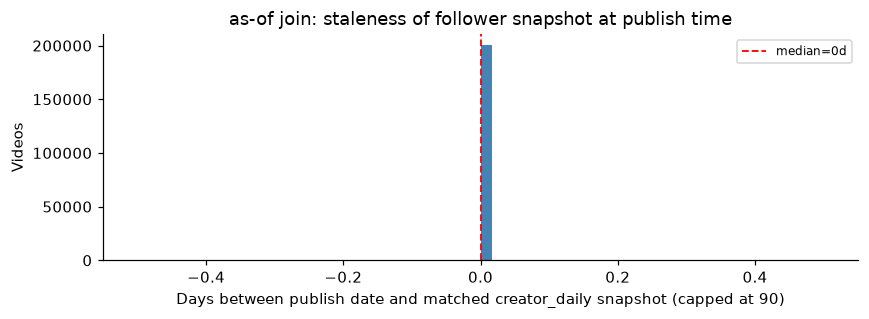

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(merged_diag["days_diff"].dropna().clip(upper=90), bins=60,
        color="steelblue", edgecolor="none")
ax.set_xlabel("Days between publish date and matched creator_daily snapshot (capped at 90)")
ax.set_ylabel("Videos")
ax.set_title("as-of join: staleness of follower snapshot at publish time")
ax.axvline(merged_diag["days_diff"].median(), color="red", linestyle="--",
           linewidth=1.2, label=f"median={merged_diag['days_diff'].median():.0f}d")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "nb03_follower_join_staleness.png", dpi=120)
plt.show()


## Split — train / test

In [7]:
seed = cfg["seed"]
train_df, test_df = train_test_split_by_creator(videos_f, "author_id",
                                                test_size=0.2, seed=seed)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])
print(f"Train: {len(train_df):,}  Test: {len(test_df):,}")


Train: 160,492  Test: 40,124


## Build feature matrix

In [8]:
features = build_features(videos_f, creator_daily, train_video_ids=train_ids)
print(f"Feature matrix: {features.shape[0]:,} rows × {features.shape[1]} columns")

# Save to data/processed/
out_path = Path("data/processed/features.parquet")
out_path.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(str(out_path), index=False)
print(f"Saved → {out_path}")


Feature matrix: 200,616 rows × 55 columns
Saved → data/processed/features.parquet


In [9]:
rel_t = build_target(engagement, videos_f, day=14, mode="relative",
                     train_video_ids=train_ids)
print(f"Relative target: {len(rel_t):,} rows  mean={rel_t['target'].mean():.4f}")


Relative target: 200,616 rows  mean=0.1424


## Feature profiles: type, null %, distribution

In [10]:
feat_cols = [c for c in features.columns if c != "video_id"]
# Use select_dtypes so Arrow-backed string columns are correctly classified
num_cols = features[feat_cols].select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in feat_cols if c not in num_cols]

profile_rows = []
for col in feat_cols:
    s = features[col]
    profile_rows.append({
        "feature": col,
        "dtype": str(s.dtype),
        "null_%": round(s.isna().mean() * 100, 1),
        "n_unique": s.nunique() if s.dtype != object else s.nunique(),
        "description": FEATURE_DESCRIPTIONS.get(col, ""),
    })
profile = pd.DataFrame(profile_rows).set_index("feature")
print(f"Total features: {len(feat_cols)}")
print(f"  Numeric: {len(num_cols)}")
print(f"  Categorical (object): {len(cat_cols)}")
print(f"  Features with >50% nulls:")
print(profile[profile["null_%"] > 50][["null_%", "dtype"]].to_string())


Total features: 54
  Numeric: 50
  Categorical (object): 4
  Features with >50% nulls:
                                 null_%    dtype
feature                                         
transcript_n_words                 59.8  float64
hook_first_sentence_len            59.8  float64
hook_first_sentence_is_question    59.8  float64


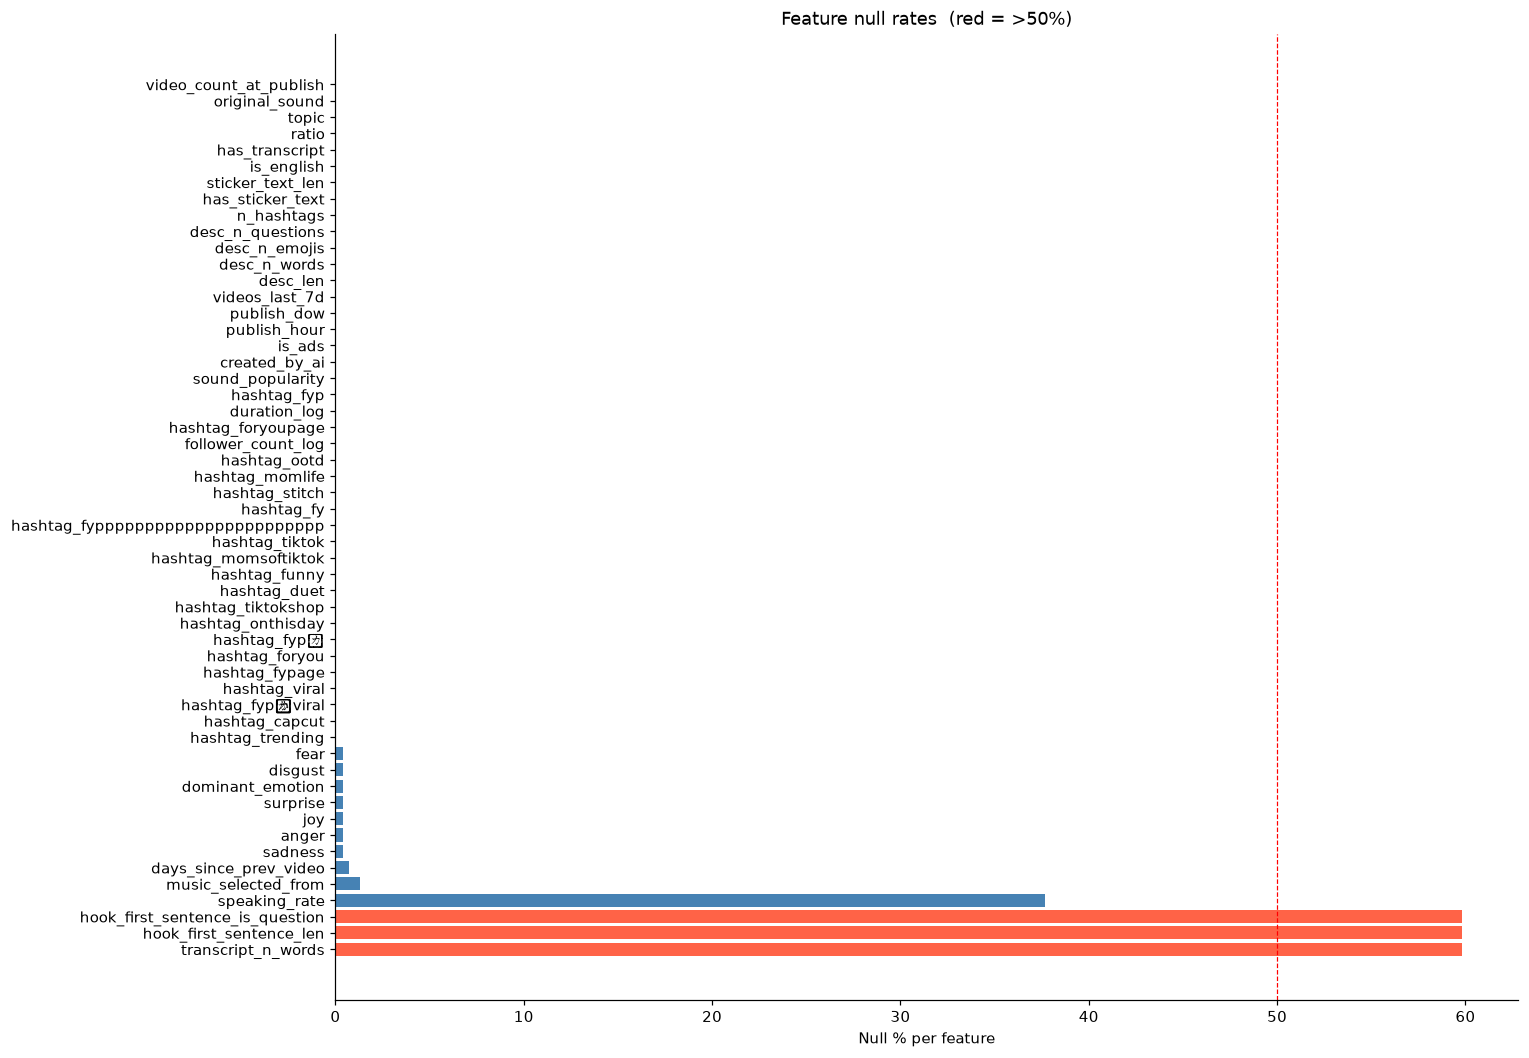

In [11]:
null_series = profile["null_%"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, max(4, len(null_series) * 0.18)))
colors = ["tomato" if v > 50 else "steelblue" for v in null_series]
ax.barh(null_series.index, null_series.values, color=colors, height=0.8)
ax.set_xlabel("Null % per feature")
ax.set_title("Feature null rates  (red = >50%)")
ax.axvline(50, color="red", linestyle="--", linewidth=0.8)
fig.tight_layout()
fig.savefig(FIGS / "nb03_null_rates.png", dpi=120)
plt.show()


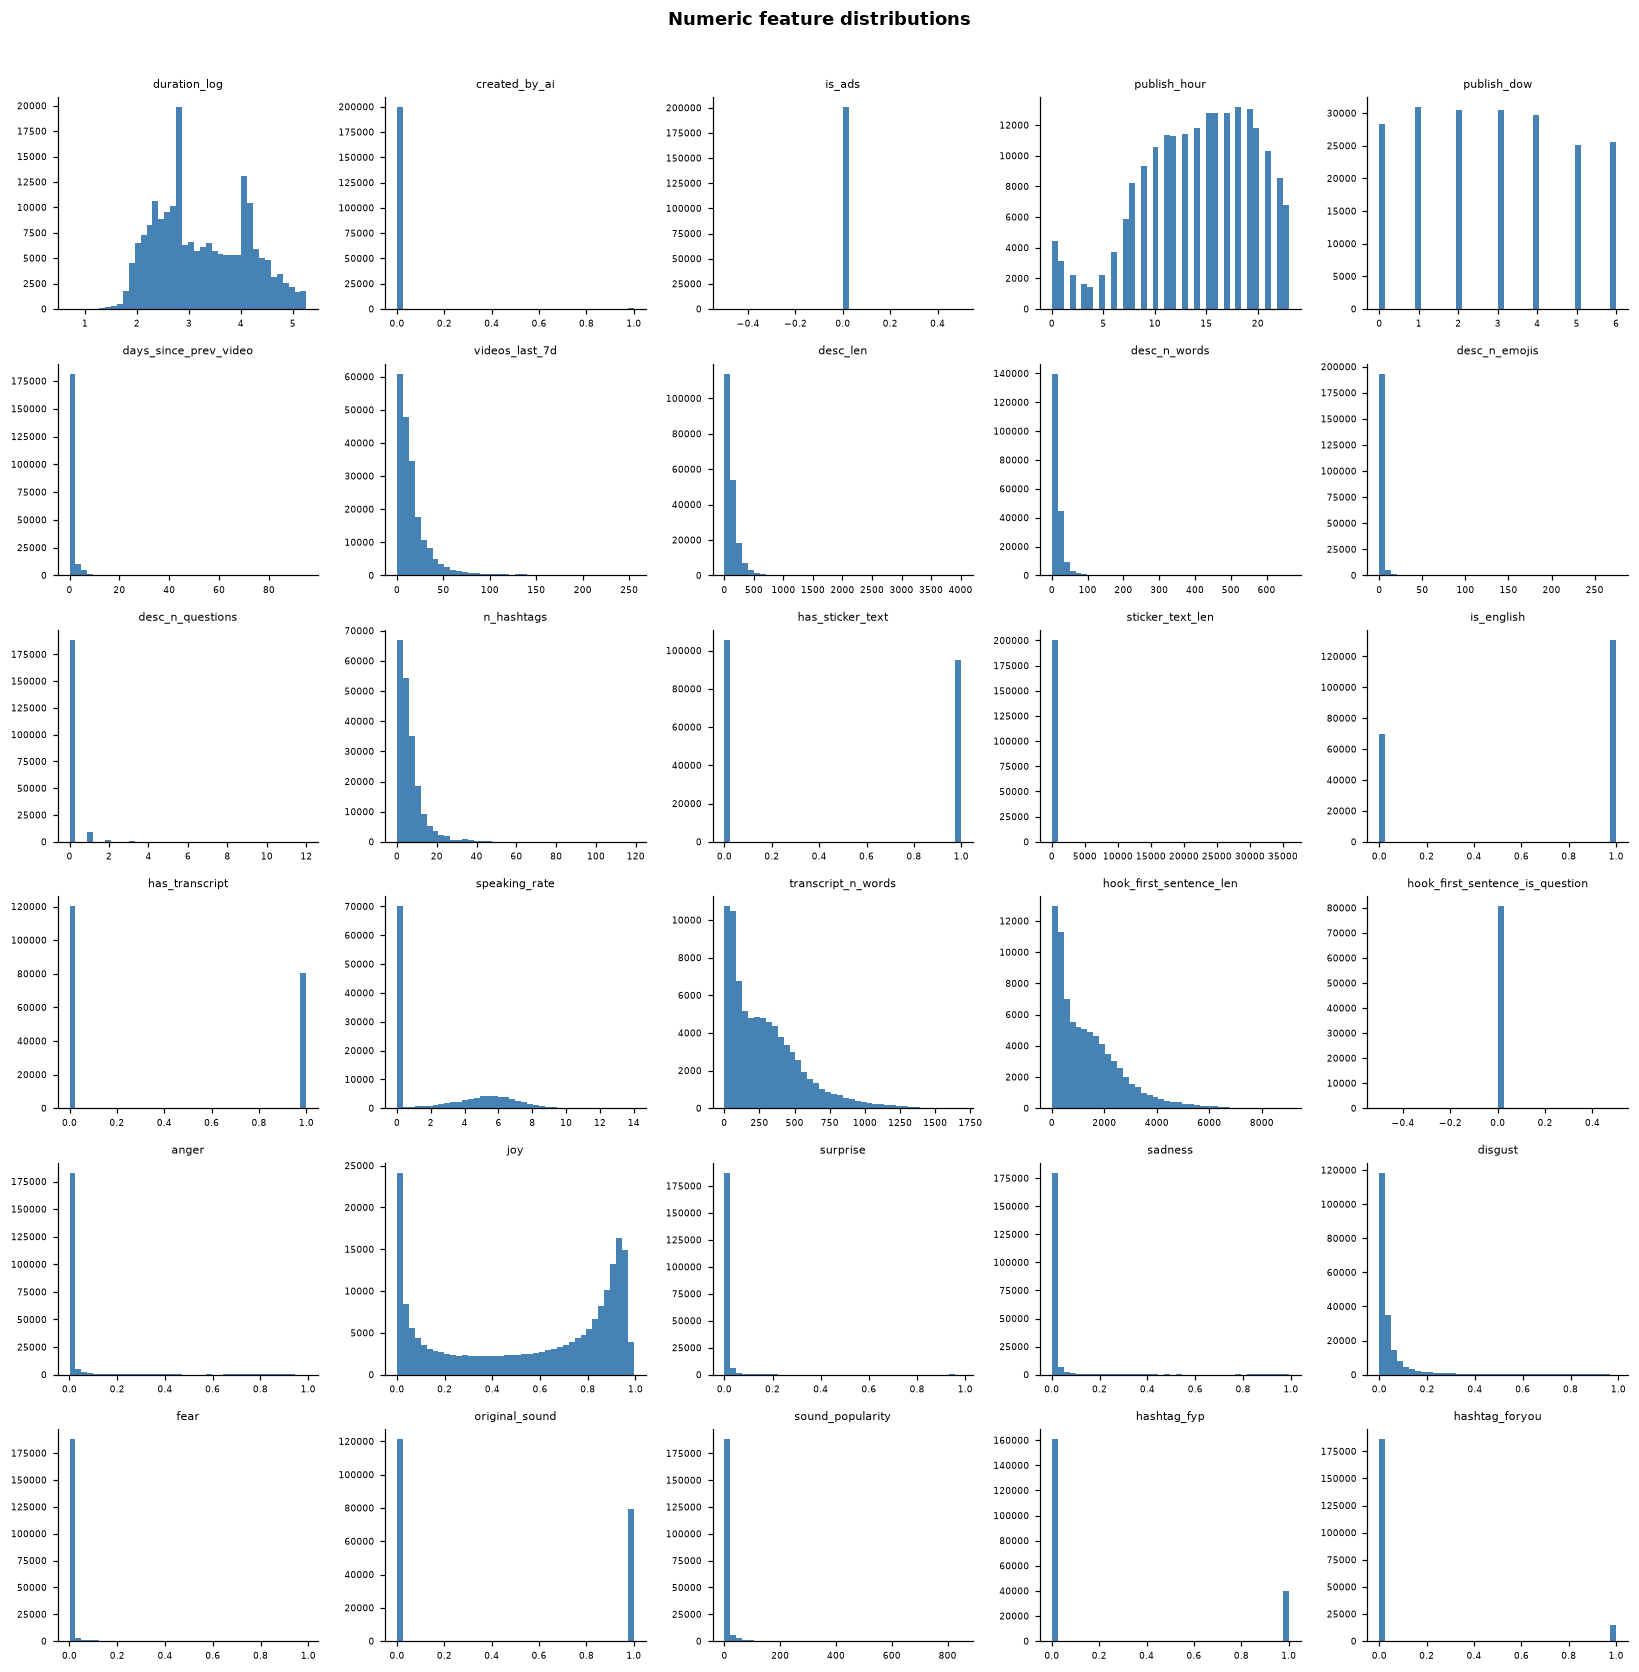

In [12]:
# Distribution histograms for numeric features (up to 30)
num_show = [c for c in num_cols if features[c].notna().sum() > 10][:30]
n = len(num_show)
ncols = 5
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 2.5))
for ax, col in zip(axes.flat, num_show):
    data = features[col].dropna()
    ax.hist(data, bins=40, color="steelblue", edgecolor="none")
    ax.set_title(col, fontsize=7)
    ax.tick_params(labelsize=6)
for ax in axes.flat[len(num_show):]:
    ax.set_visible(False)
fig.suptitle("Numeric feature distributions", fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(FIGS / "nb03_numeric_distributions.png", dpi=120, bbox_inches="tight")
plt.show()


## Correlation matrix — near-duplicate features (|r| > 0.8)

In [13]:
feat_num = features[num_cols].select_dtypes(include=[np.number])
corr = feat_num.corr(method="pearson", min_periods=100)

# Find pairs with |r| > 0.8 (excluding diagonal)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
high_corr = (
    corr.where(mask)
    .stack()
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b", 0: "pearson_r"})
)
high_corr = high_corr[high_corr["pearson_r"].abs() > 0.8].sort_values("pearson_r", ascending=False)
print(f"Feature pairs with |Pearson r| > 0.8: {len(high_corr)}")
if len(high_corr):
    display(high_corr.to_string(index=False))


Feature pairs with |Pearson r| > 0.8: 4


'         feature_a               feature_b  pearson_r\ntranscript_n_words hook_first_sentence_len   0.936078\n          desc_len            desc_n_words   0.934554\n    has_transcript           speaking_rate   0.896471\n      duration_log      transcript_n_words   0.815997'

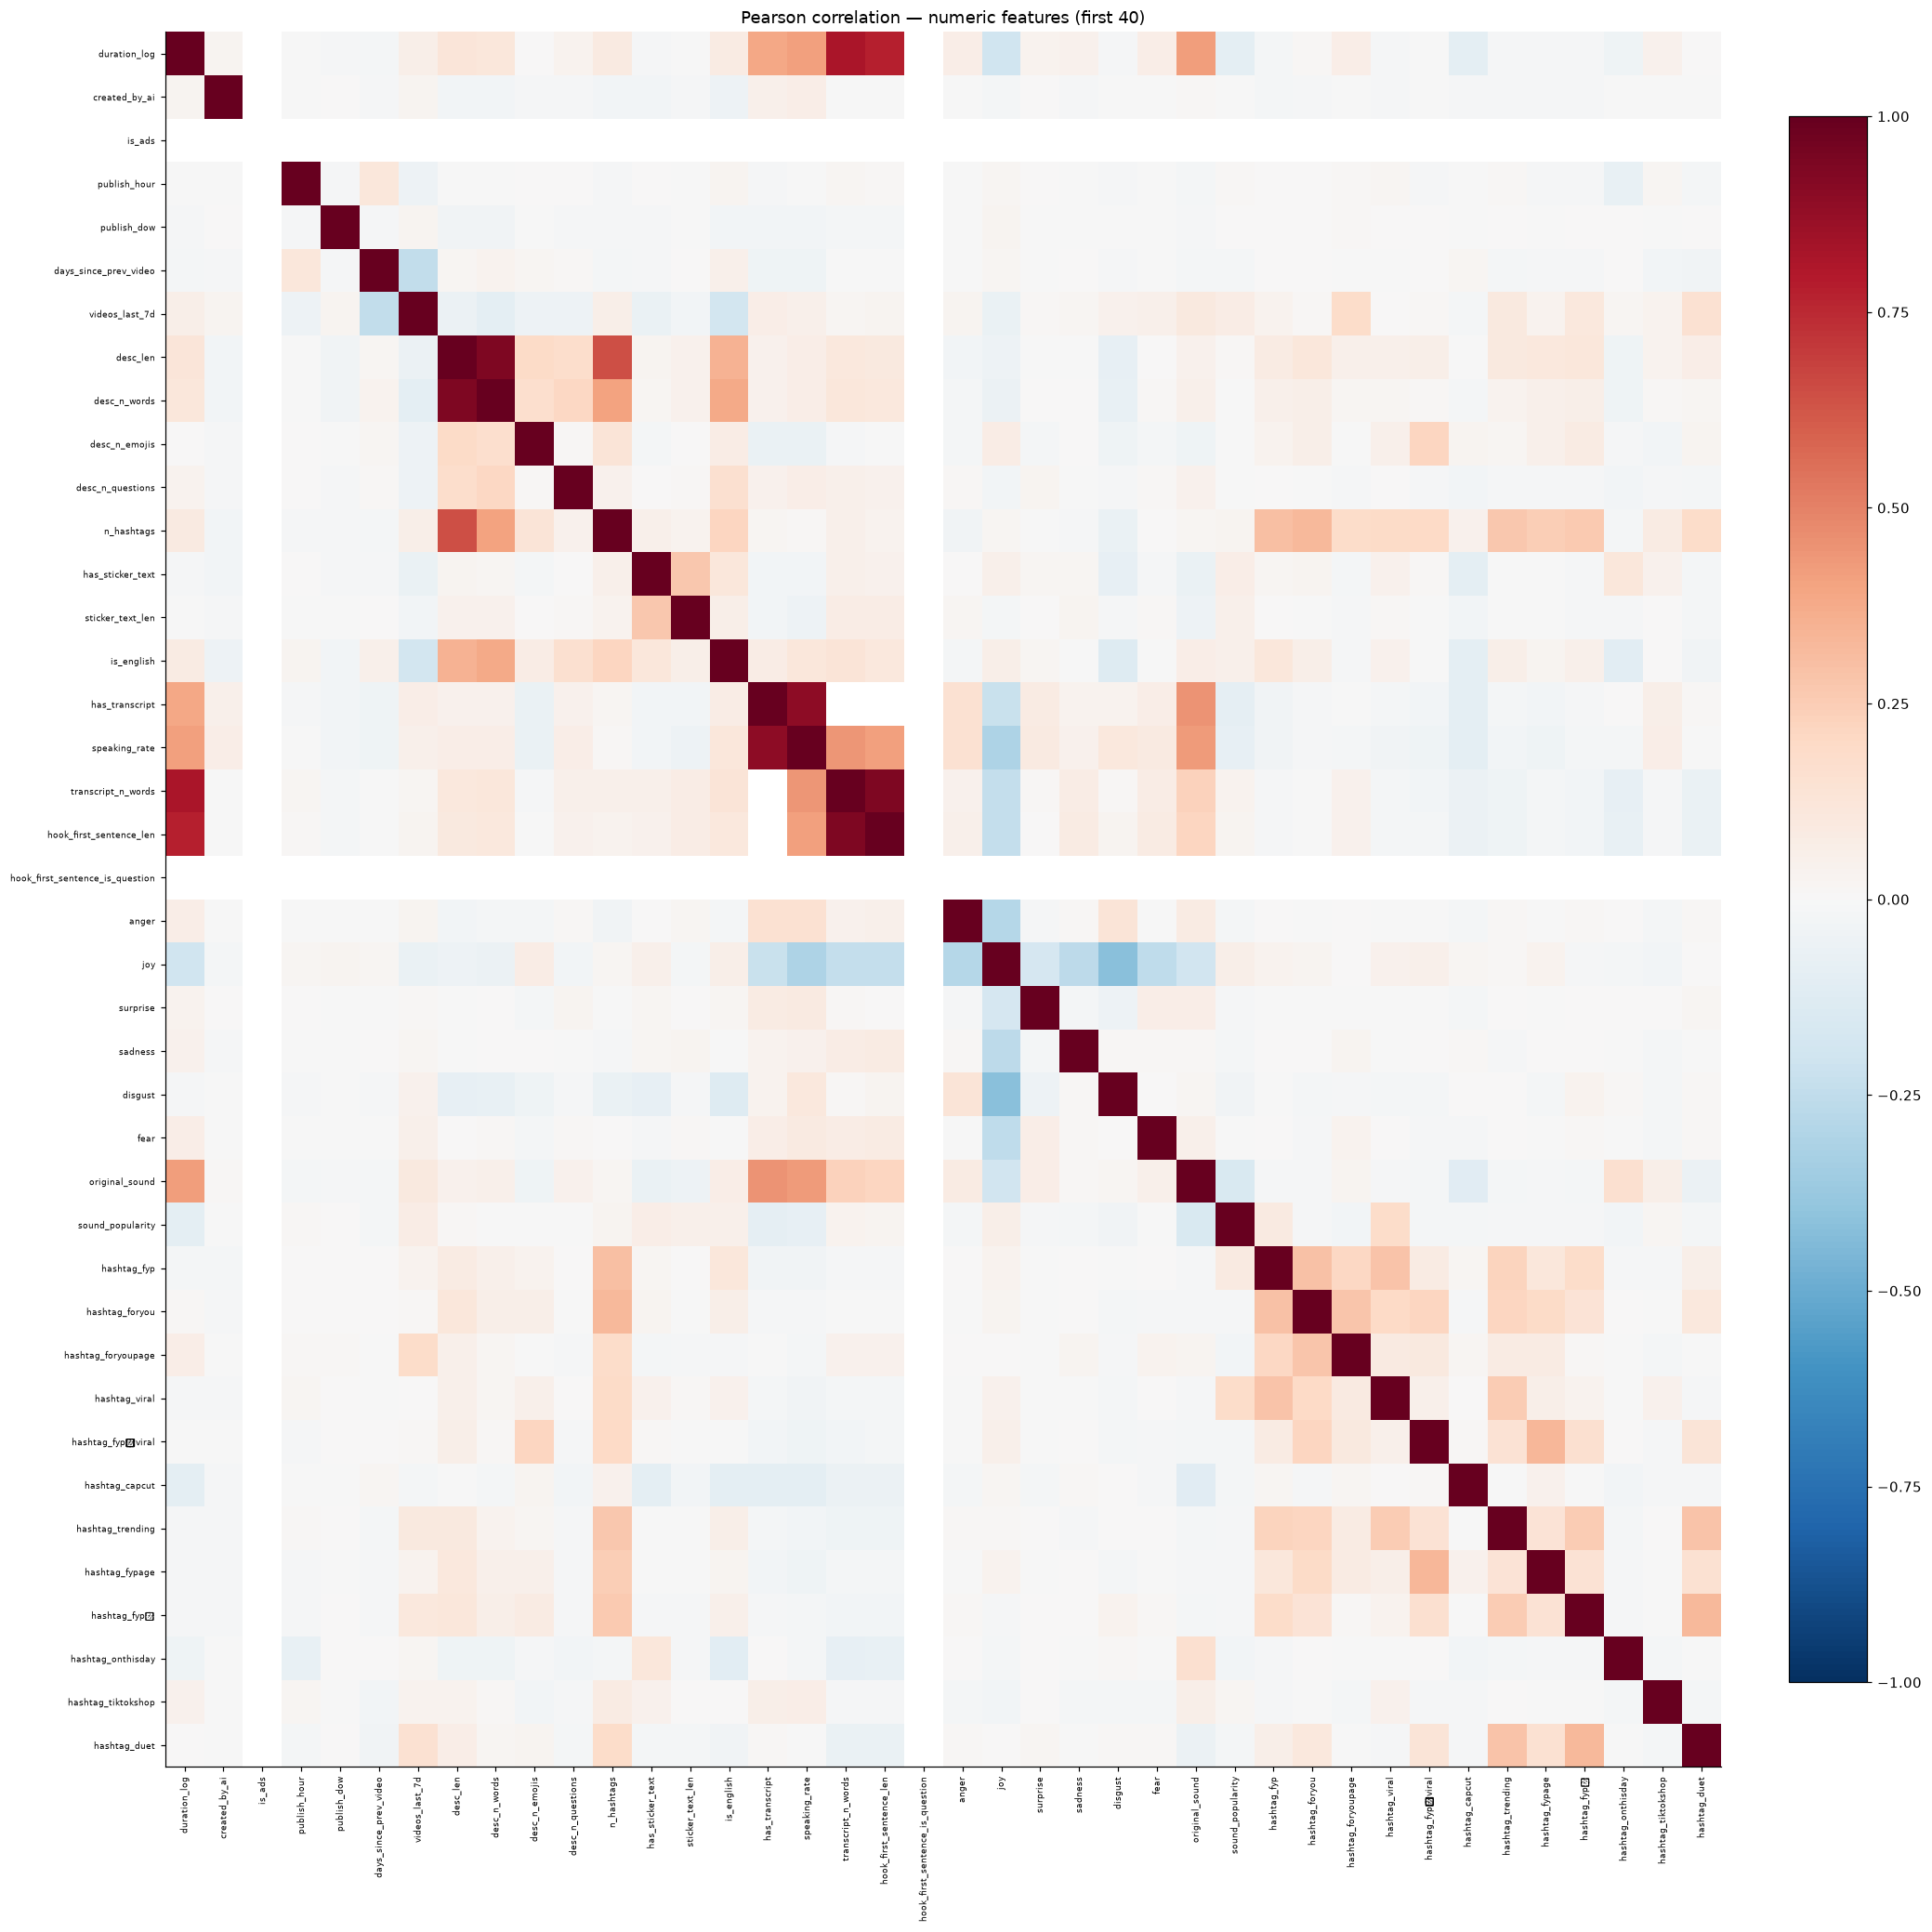

In [14]:
import matplotlib.colors as mcolors

n_num = min(len(num_cols), 40)
sub_cols = num_cols[:n_num]
sub_corr = features[sub_cols].select_dtypes(include=[np.number]).corr(min_periods=50)

fig, ax = plt.subplots(figsize=(n_num * 0.45 + 1, n_num * 0.45 + 1))
im = ax.imshow(sub_corr, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
ax.set_xticks(range(len(sub_cols))); ax.set_xticklabels(sub_cols, rotation=90, fontsize=6)
ax.set_yticks(range(len(sub_cols))); ax.set_yticklabels(sub_cols, fontsize=6)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Pearson correlation — numeric features (first 40)")
fig.tight_layout()
fig.savefig(FIGS / "nb03_correlation_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Spearman correlation with relative target (train only — sanity check)

In [15]:
merged_train = (features[features["video_id"].isin(train_ids)]
                .merge(rel_t, on="video_id"))

spearman_rows = []
for col in num_cols:
    sub = merged_train[["target", col]].dropna()
    if len(sub) < 50:
        continue
    r = sub["target"].corr(sub[col], method="spearman")
    spearman_rows.append({"feature": col, "spearman_r": round(r, 4)})

spearman_df = (pd.DataFrame(spearman_rows)
               .sort_values("spearman_r", key=abs, ascending=False)
               .reset_index(drop=True))

print("Top features by |Spearman r| with relative target (train):")
display(spearman_df.head(20).to_string(index=False))
print(f"\nTotal numeric features with >=50 train rows: {len(spearman_df)}")


Top features by |Spearman r| with relative target (train):


'              feature  spearman_r\n     sticker_text_len      0.0819\n     has_sticker_text      0.0658\n         hashtag_duet     -0.0607\ndays_since_prev_video      0.0426\n             desc_len      0.0402\n                anger      0.0382\n           is_english      0.0365\n           n_hashtags      0.0363\n         desc_n_words      0.0339\n                  joy     -0.0301\n       hashtag_capcut     -0.0271\n        speaking_rate      0.0266\n       has_transcript      0.0250\n   follower_count_log      0.0241\n              disgust      0.0217\n          publish_dow      0.0192\n             surprise      0.0192\n                 fear      0.0189\n       hashtag_stitch     -0.0187\n       original_sound      0.0172'


Total numeric features with >=50 train rows: 50


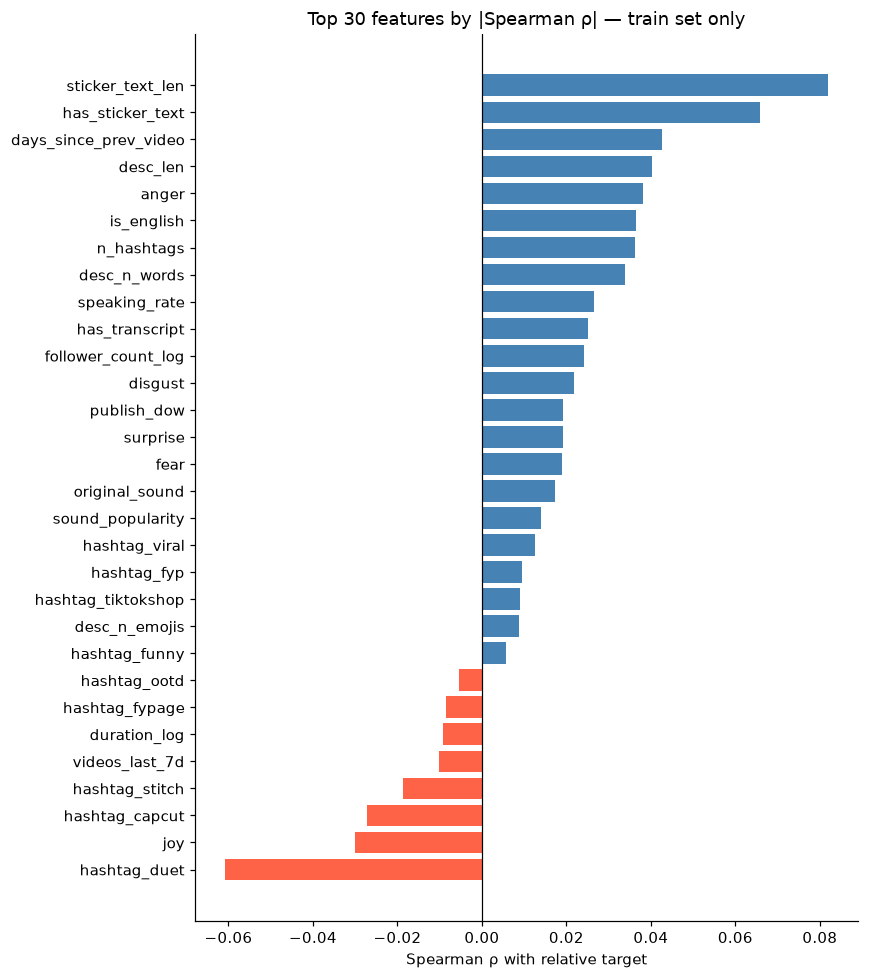

In [16]:
top_n = min(30, len(spearman_df))
fig, ax = plt.subplots(figsize=(8, max(4, top_n * 0.3)))
sp_top = spearman_df.head(top_n).sort_values("spearman_r")
colors = ["steelblue" if v >= 0 else "tomato" for v in sp_top["spearman_r"]]
ax.barh(sp_top["feature"], sp_top["spearman_r"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman ρ with relative target")
ax.set_title(f"Top {top_n} features by |Spearman ρ| — train set only")
fig.tight_layout()
fig.savefig(FIGS / "nb03_spearman_vs_target.png", dpi=120)
plt.show()


## Per-creator constancy — which features don't vary within a creator?

In [17]:
# For each feature, compute the fraction of creators where the feature
# is (nearly) constant — std == 0 or only 1 unique non-null value.
# A feature constant within a creator is useless for a per-creator model.

feat_w_author = features.merge(videos_f[["video_id", "author_id"]], on="video_id")

constancy_rows = []
for col in feat_cols:
    if col == "video_id":
        continue
    null_pct = features[col].isna().mean() * 100
    if features[col].dtype == object:
        # categorical: constant if all values the same within creator
        per_creator_nunique = feat_w_author.groupby("author_id")[col].nunique()
    else:
        per_creator_nunique = (
            feat_w_author.groupby("author_id")[col]
            .apply(lambda s: s.dropna().nunique() if s.notna().any() else 0)
        )
    frac_constant = (per_creator_nunique <= 1).mean()
    constancy_rows.append({
        "feature": col,
        "null_%": round(null_pct, 1),
        "frac_creators_constant": round(frac_constant, 3),
    })

const_df = (pd.DataFrame(constancy_rows)
            .sort_values("frac_creators_constant", ascending=False)
            .reset_index(drop=True))

print("Features sorted by fraction of creators with constant value:")
display(const_df.to_string(index=False))


Features sorted by fraction of creators with constant value:


'                          feature  null_%  frac_creators_constant\n  hook_first_sentence_is_question    59.8                   1.000\n                           is_ads     0.0                   1.000\n                  hashtag_momlife     0.0                   0.888\n                       hashtag_fy     0.0                   0.872\n                    created_by_ai     0.0                   0.862\n             hashtag_momsoftiktok     0.0                   0.859\nhashtag_fyppppppppppppppppppppppp     0.0                   0.856\n                   hashtag_tiktok     0.0                   0.854\n                   hashtag_stitch     0.0                   0.833\n                     hashtag_fypシ     0.0                   0.831\n                     hashtag_duet     0.0                   0.817\n                     hashtag_ootd     0.0                   0.814\n               hashtag_tiktokshop     0.0                   0.797\n                 hashtag_trending     0.0                   0

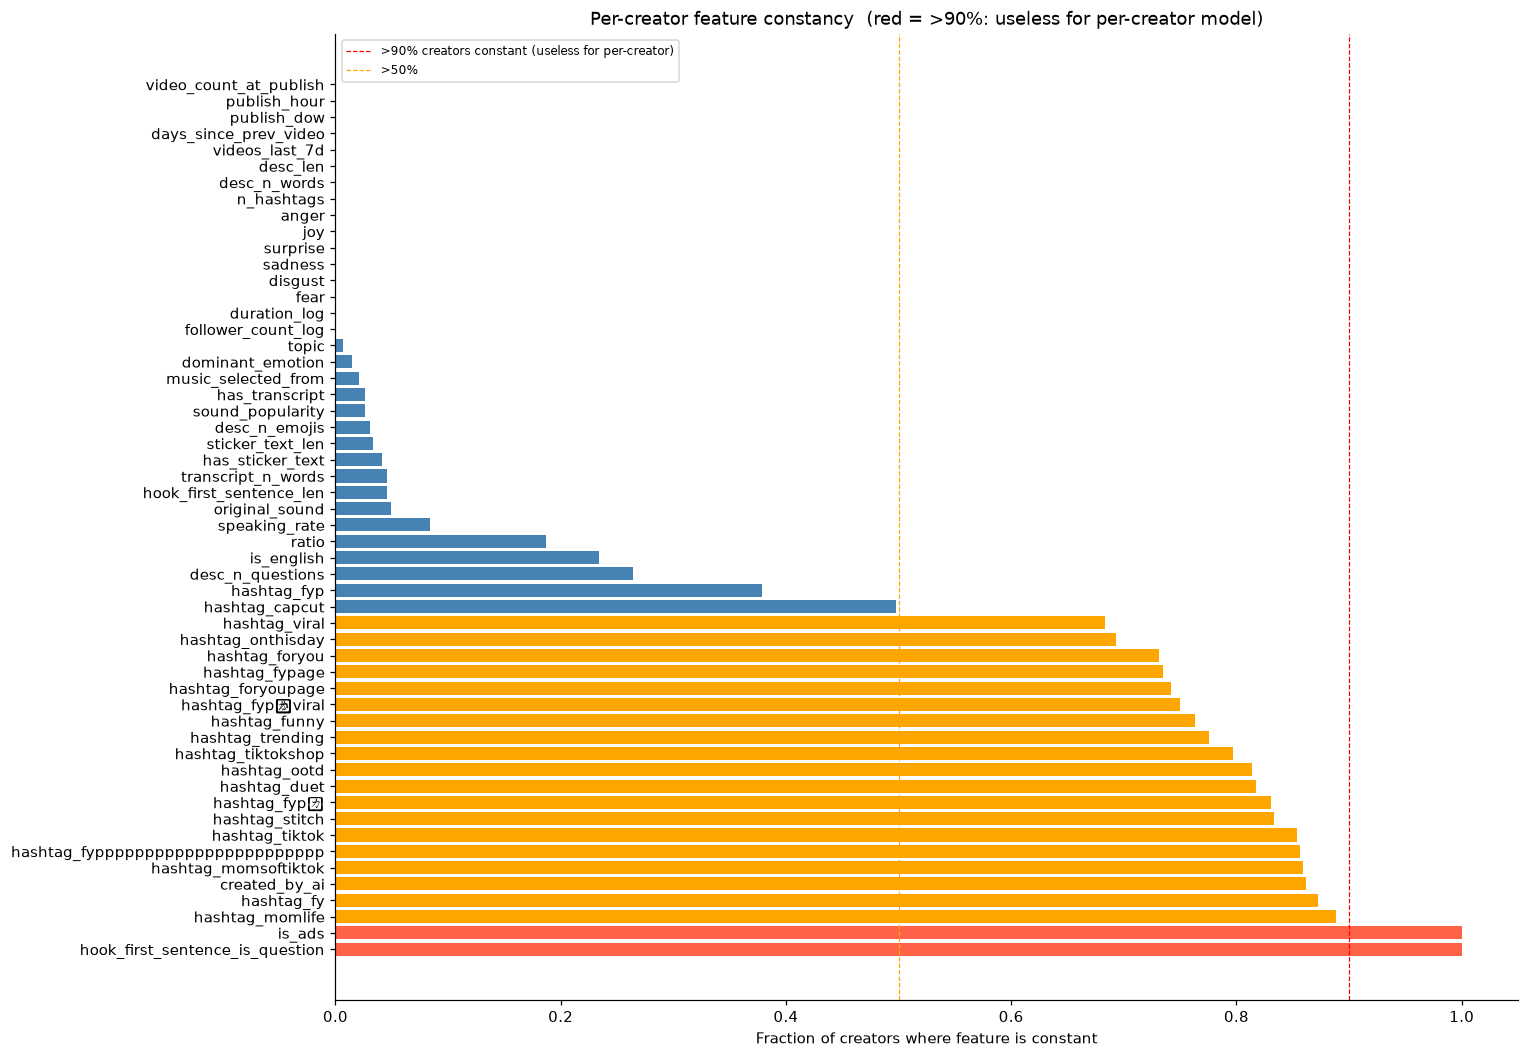

In [18]:
fig, ax = plt.subplots(figsize=(14, max(4, len(const_df) * 0.18)))
colors = ["tomato" if v > 0.9 else ("orange" if v > 0.5 else "steelblue")
          for v in const_df["frac_creators_constant"]]
ax.barh(const_df["feature"], const_df["frac_creators_constant"], color=colors, height=0.8)
ax.axvline(0.9, color="red", linestyle="--", linewidth=0.8, label=">90% creators constant (useless for per-creator)")
ax.axvline(0.5, color="orange", linestyle="--", linewidth=0.8, label=">50%")
ax.set_xlabel("Fraction of creators where feature is constant")
ax.set_title("Per-creator feature constancy  (red = >90%: useless for per-creator model)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "nb03_creator_constancy.png", dpi=120)
plt.show()


## Summary table: null % and per-creator constancy

In [19]:
summary = (profile[["null_%", "dtype"]]
           .join(const_df.set_index("feature")[["frac_creators_constant"]])
           .sort_values("frac_creators_constant", ascending=False))
print("Full feature audit table:")
display(summary)


Full feature audit table:


,null_%,dtype,frac_creators_constant
feature,,,
hook_first_sentence_is_question,59.8,float64,1.000
is_ads,0.0,int8,1.000
hashtag_momlife,0.0,int8,0.888
hashtag_fy,0.0,int8,0.872
created_by_ai,0.0,int8,0.862
hashtag_momsoftiktok,0.0,int8,0.859
hashtag_fyppppppppppppppppppppppp,0.0,int8,0.856
hashtag_tiktok,0.0,int8,0.854
hashtag_stitch,0.0,int8,0.833
